# TPI · Módulo 4 — Clasificación y evaluación
**Detección de leucemia linfoblástica aguda en frotis de sangre periférica · Grupo 12 · PSIB**

**Objetivo.** Construir un clasificador binario interpretable (**patológica / no patológica**) mediante reglas de umbral sobre los descriptores del Módulo 3 y **votación mayoritaria**, sin redes neuronales ni modelos de clasificación de aprendizaje automático.

**Criterios del anteproyecto:** división 70/30; Mann–Whitney con FDR; ROC y selección de características no redundantes; umbrales por índice de Youden y una alternativa con sensibilidad prioritaria; matriz de confusión, sensibilidad, especificidad, exactitud y precisión sobre prueba independiente.

**Independencia del notebook:** necesita exclusivamente `modulo3_descriptores.csv`. Se puede ejecutar en un Colab nuevo. Todos los umbrales se calculan a partir de los datos de **ajuste**, nunca de prueba.

## 1. Carga y control de datos
Los nombres originales de clase se mantienen. Los 28 descriptores proceden del Módulo 3; las columnas identificadoras no se usan para clasificar. **No hay identificador de paciente** en el CSV, por lo que el reparto 70/30 se realiza por imagen, con posible dependencia entre imágenes de un mismo paciente (limitación que debe informarse).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, spearmanr
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (roc_curve, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score)

SEMILLA = 42
CSV = Path('modulo3_descriptores.csv')
if not CSV.exists():
    try:
        from google.colab import files
        print('Subí modulo3_descriptores.csv:')
        files.upload()
    except ImportError:
        pass
if not CSV.exists():
    raise FileNotFoundError('Ubicá modulo3_descriptores.csv en el directorio de ejecución.')

desc = pd.read_csv(CSV)
IDENTIFICADORES = ['archivo', 'subtipo', 'clase']
assert set(IDENTIFICADORES).issubset(desc.columns), 'Faltan columnas de identificación.'
FEATURES = [c for c in desc.columns if c not in IDENTIFICADORES]
assert len(FEATURES) > 0 and all(pd.api.types.is_numeric_dtype(desc[c]) for c in FEATURES)
assert desc['clase'].isin(['patológica', 'no patológica']).all()
assert not desc.duplicated(['archivo', 'subtipo']).any()
assert np.isfinite(desc[FEATURES].to_numpy(dtype=float)).all()

desc['y'] = (desc['clase'] == 'patológica').astype(int)
print(f'Imágenes: {len(desc)} · Descriptores: {len(FEATURES)}')
print(desc.groupby(['clase', 'subtipo']).size().to_string())
print('Identificador de paciente disponible:', 'paciente' in desc.columns)

Imágenes: 3256 · Descriptores: 28
clase          subtipo
no patológica  Benign     504
patológica     Early      985
               Pre        963
               Pro        804
Identificador de paciente disponible: False


## 2. Separación independiente: 70 % ajuste / 30 % prueba
La estratificación preserva la proporción binaria de clases. **Nunca se consulta el conjunto de prueba para seleccionar características, umbrales ni configuraciones.** La validación cruzada interna utiliza solamente el 70 % de ajuste. Se mantiene la correspondencia por nombre de archivo para que la partición pueda reproducirse en otros módulos.

In [2]:
ajuste, prueba = train_test_split(
    desc, test_size=0.30, stratify=desc['y'], random_state=SEMILLA
)
ajuste, prueba = ajuste.copy(), prueba.copy()
assert set(ajuste['archivo']).isdisjoint(set(prueba['archivo']))
print('AJUSTE:', len(ajuste), '\n', ajuste['clase'].value_counts().to_string())
print('PRUEBA:', len(prueba), '\n', prueba['clase'].value_counts().to_string())

pd.concat([
    ajuste[['archivo', 'subtipo', 'clase']].assign(particion='ajuste'),
    prueba[['archivo', 'subtipo', 'clase']].assign(particion='prueba')
]).to_csv('modulo4_particiones.csv', index=False)

AJUSTE: 2279 
 clase
patológica       1926
no patológica     353
PRUEBA: 977 
 clase
patológica       826
no patológica    151


## 3. Análisis estadístico y características candidatas
Para cada descriptor se compara su distribución entre clases mediante la **prueba bilateral de Mann–Whitney** (sin exigir normalidad). Se controla la tasa esperada de falsos descubrimientos usando **Benjamini–Hochberg (FDR, α = 0,05)**. Se calcula además el AUC de ROC sobre ajuste, con orientación invertida si la clase patológica presenta valores menores. Este AUC se utiliza como medida de separación **univariada**, no de capacidad clínica final.

La significación estadística por sí sola no basta: la selección posterior elimina descriptores redundantes mediante Spearman y conserva un número pequeño para que la votación sea interpretable.

In [3]:
def evaluar_descriptores(datos, columnas):
    y = datos['y'].to_numpy()
    filas = []
    for c in columnas:
        x = datos[c].to_numpy(dtype=float)
        benignos, patologicos = x[y == 0], x[y == 1]
        _, p = mannwhitneyu(patologicos, benignos, alternative='two-sided')
        auc_original = roc_auc_score(y, x)
        signo = 1 if auc_original >= 0.5 else -1
        filas.append({'descriptor': c, 'p': p,
                      'auc_orientado': max(auc_original, 1 - auc_original),
                      'direccion': signo,
                      'mediana_benigna': float(np.median(benignos)),
                      'mediana_patologica': float(np.median(patologicos))})
    t = pd.DataFrame(filas)
    t['q_fdr'] = multipletests(t['p'], alpha=0.05, method='fdr_bh')[1]
    return t.sort_values(['q_fdr', 'auc_orientado'], ascending=[True, False]).reset_index(drop=True)

estadistica = evaluar_descriptores(ajuste, FEATURES)
display(estadistica.round(4))
print('Descriptores con FDR < 0,05:', (estadistica.q_fdr < 0.05).sum())
estadistica.to_csv('modulo4_estadistica_ajuste.csv', index=False)

,descriptor,p,auc_orientado,direccion,mediana_benigna,mediana_patologica,q_fdr
0,b_desvio,0.0000,0.9199,-1,11.6464,7.7853,0.0000
1,S_desvio,0.0000,0.9167,-1,27.0257,17.0601,0.0000
2,a_desvio,0.0000,0.8709,-1,9.6506,6.9104,0.0000
3,glcm_correlacion_d3,0.0000,0.8283,1,0.1867,0.3474,0.0000
4,S_rel,0.0000,0.8103,-1,3.1401,2.0443,0.0000
5,H_desvio,0.0000,0.8043,-1,3.2287,2.4178,0.0000
6,glcm_correlacion_d1,0.0000,0.7808,1,0.5320,0.6593,0.0000
7,glcm_energia_d3,0.0000,0.7333,-1,0.1011,0.0827,0.0000
8,glcm_energia_d1,0.0000,0.7122,-1,0.1074,0.0895,0.0000
9,area,0.0000,0.7018,1,351.0000,432.0000,0.0000


Descriptores con FDR < 0,05: 22


## 4. Reglas por ROC y selección de parámetros
Para cada descriptor se genera una regla **patológica si signo × descriptor ≥ umbral**. El signo se determina en ajuste a partir de la dirección del AUC.

Se comparan dos criterios de umbralización en ajuste:
- **Youden:** máximo de sensibilidad + especificidad − 1.
- **Sensibilidad objetivo:** entre los umbrales ROC que alcanzan una sensibilidad prefijada, se elige el de mayor especificidad.

Los valores 0,90 y 0,95 de sensibilidad objetivo, el número de descriptores (3, 5 o 7) y los límites de redundancia de Spearman (0,80 o 0,90) son **candidatos de un barrido acotado, no verdades bibliográficas**. Se eligen por **validación cruzada estratificada de 3 particiones dentro de ajuste**. Se utiliza número impar de reglas para evitar empates. El nivel FDR = 0,05 corresponde al criterio estadístico convencional, y Youden es un criterio ROC definido matemáticamente, no un umbral inventado.

In [4]:
def elegir_features(datos, tabla, n, limite_corr):
    candidatos = tabla[tabla.q_fdr < 0.05].sort_values('auc_orientado', ascending=False)
    seleccion = []
    for c in candidatos['descriptor']:
        # Evita reglas prácticamente duplicadas dentro de ajuste.
        if all(abs(spearmanr(datos[c], datos[prev]).statistic) < limite_corr
               for prev in seleccion):
            seleccion.append(c)
        if len(seleccion) == n:
            break
    return seleccion


def umbral_roc(y, x, modo):
    fpr, tpr, thr = roc_curve(y, x, drop_intermediate=False)
    validos = np.isfinite(thr)
    if modo == 'youden':
        punt = tpr - fpr
        punt[~validos] = -np.inf
        idx = np.argmax(punt)
    else:
        objetivo = float(modo)  # 0.90 / 0.95
        posibles = np.flatnonzero(validos & (tpr >= objetivo))
        if not len(posibles):
            raise ValueError('No existe umbral que alcance la sensibilidad solicitada.')
        # Máxima especificidad; desempate por mayor sensibilidad.
        idx = min(posibles, key=lambda i: (fpr[i], -tpr[i]))
    return float(thr[idx])


def ajustar_reglas(datos, seleccion, modo):
    y = datos['y'].to_numpy()
    reglas = []
    for c in seleccion:
        x = datos[c].to_numpy(dtype=float)
        signo = 1 if roc_auc_score(y, x) >= 0.5 else -1
        reglas.append({'descriptor': c, 'signo': int(signo),
                       'umbral': umbral_roc(y, signo * x, modo)})
    return reglas


def predecir_votacion(datos, reglas):
    if len(reglas) == 0 or len(reglas) % 2 == 0:
        raise ValueError('La votación necesita un número impar y no nulo de reglas.')
    votos = np.column_stack([
        (r['signo'] * datos[r['descriptor']].to_numpy(dtype=float) >= r['umbral'])
        for r in reglas
    ])
    return (votos.sum(axis=1) > len(reglas) // 2).astype(int)


def metricas(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'sensibilidad': tp / (tp + fn) if tp + fn else np.nan,
            'especificidad': tn / (tn + fp) if tn + fp else np.nan,
            'exactitud': accuracy_score(y, pred),
            'precision_positiva': precision_score(y, pred, zero_division=0),
            'f1': f1_score(y, pred, zero_division=0),
            'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn)}

### 4.1 Barrido de configuraciones dentro del conjunto de ajuste
En cada partición se repite **todo** el procedimiento (Mann–Whitney, FDR, selección de descriptores, dirección ROC y umbrales) utilizando únicamente el subconjunto de entrenamiento; las métricas se calculan en la partición interna de validación. Esto evita que la selección aproveche indirectamente los datos que pretende evaluar.

La prioridad de tamizaje se define **antes de mirar prueba**: entre las configuraciones con sensibilidad promedio de validación ≥ 0,90, elegir la de mayor especificidad; si ninguna lo consigue, elegir la de mayor sensibilidad y, en empate, la de mayor especificidad. Los resultados de CV son exploratorios; las métricas finales se informan solo en prueba.

In [5]:
from itertools import product

N_REGLAS = [3, 5, 7]
LIMITES_CORR = [0.80, 0.90]
MODOS = ['youden', 0.90, 0.95]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
resultados_cv = []

for n_reglas, limite_corr, modo in product(N_REGLAS, LIMITES_CORR, MODOS):
    mediciones = []
    for idx_ent, idx_val in cv.split(ajuste, ajuste['y']):
        ent = ajuste.iloc[idx_ent]
        val = ajuste.iloc[idx_val]
        tabla_ent = evaluar_descriptores(ent, FEATURES)
        elegidas = elegir_features(ent, tabla_ent, n_reglas, limite_corr)
        if len(elegidas) != n_reglas:
            mediciones = []
            break  # Configuración no viable sin suficientes características independientes.
        reglas = ajustar_reglas(ent, elegidas, modo)
        pred = predecir_votacion(val, reglas)
        mediciones.append(metricas(val['y'].to_numpy(), pred))
    if mediciones:
        resultados_cv.append({'n_reglas': n_reglas,
                              'limite_corr': limite_corr,
                              'modo': str(modo),
                              'sensibilidad_cv': np.mean([m['sensibilidad'] for m in mediciones]),
                              'especificidad_cv': np.mean([m['especificidad'] for m in mediciones]),
                              'exactitud_cv': np.mean([m['exactitud'] for m in mediciones])})

res_cv = pd.DataFrame(resultados_cv)
if res_cv.empty:
    raise ValueError('No hay configuraciones viables: revisar FDR y redundancia en ajuste.')

viables = res_cv[res_cv.sensibilidad_cv >= 0.90]
if len(viables):
    ordenadas = viables.sort_values(
        ['especificidad_cv', 'sensibilidad_cv', 'n_reglas'],
        ascending=[False, False, True])
    criterio = 'Sensibilidad CV >= 0,90 y máxima especificidad CV'
else:
    ordenadas = res_cv.sort_values(
        ['sensibilidad_cv', 'especificidad_cv', 'n_reglas'],
        ascending=[False, False, True])
    criterio = 'Ninguna alcanza 0,90: máxima sensibilidad CV disponible'

mejor = ordenadas.iloc[0]
print('Criterio de selección:', criterio)
display(res_cv.sort_values('sensibilidad_cv', ascending=False).round(3))
print('\nConfiguración seleccionada (solo ajuste):')
display(pd.DataFrame([mejor]).round(3))
res_cv.to_csv('modulo4_barrido_ajuste.csv', index=False)

Criterio de selección: Sensibilidad CV >= 0,90 y máxima especificidad CV


,n_reglas,limite_corr,modo,sensibilidad_cv,especificidad_cv,exactitud_cv
17,7,0.9,0.95,0.995,0.283,0.885
14,7,0.8,0.95,0.995,0.283,0.885
8,5,0.8,0.95,0.994,0.371,0.897
11,5,0.9,0.95,0.994,0.371,0.897
13,7,0.8,0.9,0.993,0.433,0.906
16,7,0.9,0.9,0.993,0.433,0.906
5,3,0.9,0.95,0.984,0.490,0.907
10,5,0.9,0.9,0.984,0.532,0.914
7,5,0.8,0.9,0.984,0.532,0.914
2,3,0.8,0.95,0.984,0.490,0.907



Configuración seleccionada (solo ajuste):


,n_reglas,limite_corr,modo,sensibilidad_cv,especificidad_cv,exactitud_cv
6,5,0.8,youden,0.944,0.759,0.916


## 5. Ajuste final de reglas sobre el 70 % de ajuste
Con la configuración elegida en validación cruzada, se vuelve a calcular la selección de descriptores y sus umbrales utilizando **todo el conjunto de ajuste**. No se modificará la configuración tras observar prueba. La tabla de reglas informa explícitamente variable, dirección y umbral, para facilitar su explicación y su implementación posterior en la interfaz.

Descriptores seleccionados: ['b_desvio', 'glcm_correlacion_d3', 'S_rel', 'H_desvio', 'glcm_energia_d3']


,descriptor,signo,umbral,criterio
0,b_desvio,-1,-9.275935,valor <= -umbral
1,glcm_correlacion_d3,1,0.250013,valor >= umbral
2,S_rel,-1,-2.759120,valor <= -umbral
3,H_desvio,-1,-2.876793,valor <= -umbral
4,glcm_energia_d3,-1,-0.095242,valor <= -umbral


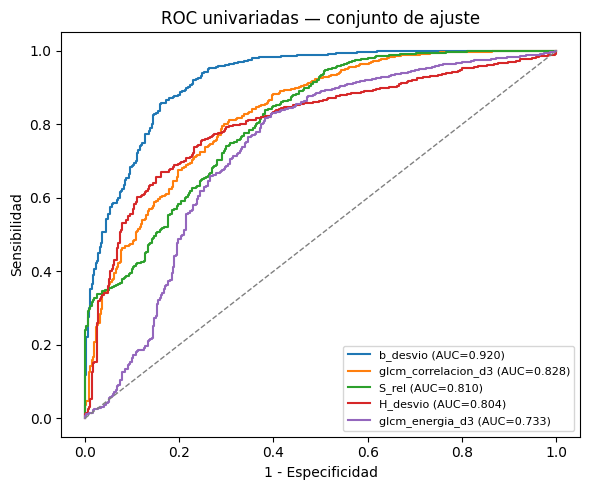

In [6]:
n_final = int(mejor['n_reglas'])
corr_final = float(mejor['limite_corr'])
modo_final = mejor['modo'] if mejor['modo'] == 'youden' else float(mejor['modo'])
seleccionadas = elegir_features(ajuste, estadistica, n_final, corr_final)
if len(seleccionadas) != n_final:
    raise ValueError('No se pudo mantener el número de reglas al reajustar.')
reglas_finales = ajustar_reglas(ajuste, seleccionadas, modo_final)

tabla_reglas = pd.DataFrame(reglas_finales)
tabla_reglas['criterio'] = np.where(
    tabla_reglas['signo'] == 1, 'valor >= umbral', 'valor <= -umbral'
)
print('Descriptores seleccionados:', seleccionadas)
display(tabla_reglas)

# ROC univariadas sobre AJUSTE, para interpretar las reglas.
plt.figure(figsize=(6, 5))
for r in reglas_finales:
    score = r['signo'] * ajuste[r['descriptor']].to_numpy()
    fpr, tpr, _ = roc_curve(ajuste['y'], score)
    auc = roc_auc_score(ajuste['y'], score)
    plt.plot(fpr, tpr, label=f"{r['descriptor']} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
plt.xlabel('1 - Especificidad')
plt.ylabel('Sensibilidad')
plt.title('ROC univariadas — conjunto de ajuste')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Evaluación final sobre el 30 % de prueba
**Única evaluación del clasificador congelado.** Se informan sensibilidad, especificidad, exactitud, precisión positiva y matriz de confusión (también F1 por el desbalance de clases). La clase positiva es **patológica**. Estas métricas son **por imagen**, no por paciente y no constituyen una validación clínica.

Un umbral seleccionado para priorizar sensibilidad no garantiza alcanzar la sensibilidad objetivo en datos de prueba: allí se informa lo observado, sin reajustes.

Desempeño final — conjunto independiente de prueba:


,sensibilidad,especificidad,exactitud,precision_positiva,f1,TP,TN,FP,FN
0,0.937,0.7815,0.913,0.9591,0.9479,774,118,33,52


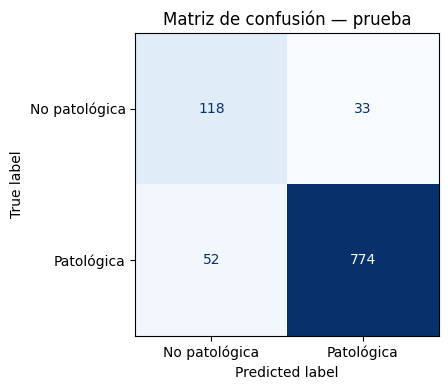

In [7]:
y_prueba = prueba['y'].to_numpy()
pred_prueba = predecir_votacion(prueba, reglas_finales)
resultado = metricas(y_prueba, pred_prueba)
print('Desempeño final — conjunto independiente de prueba:')
display(pd.DataFrame([resultado]).round(4))

cm = confusion_matrix(y_prueba, pred_prueba, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No patológica', 'Patológica']
).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Matriz de confusión — prueba')
plt.tight_layout()
plt.show()

predicciones = prueba[['archivo', 'subtipo', 'clase']].copy()
predicciones['prediccion'] = np.where(pred_prueba == 1, 'patológica', 'no patológica')
predicciones.to_csv('modulo4_predicciones_prueba.csv', index=False)

## 7. Exportación de las reglas y conclusiones
El archivo JSON contiene los descriptores, signos y umbrales **ajustados** que deberá utilizar la interfaz del Módulo 5. **No** hace falta entrenar nada al recibir una imagen nueva: se calculan los mismos descriptores y se aplican estas reglas fijas.

**Limitaciones a informar en el trabajo:** (1) división por imagen debido a la ausencia de ID de paciente en el CSV; (2) desbalance entre clases; (3) dependencia de la calidad de segmentación del Módulo 2 y posibles efectos de tinción; (4) indicadores de desempeño internos, no estimaciones de rendimiento clínico generalizable; (5) selección exploratoria de hiperparámetros mediante CV exclusivamente en ajuste.

In [8]:
modelo = {
    'clase_positiva': 'patológica',
    'metodo': 'reglas_univariadas_ROC_votacion_mayoritaria',
    'n_reglas': len(reglas_finales),
    'modo_umbral': modo_final,
    'umbral_correlacion_spearman': corr_final,
    'semilla_particion': SEMILLA,
    'reglas': reglas_finales,
    'descripcion': 'Usar exclusivamente con descriptores calculados mediante el mismo pipeline de Módulos 1-3.'
}
with open('modulo4_reglas_finales.json', 'w', encoding='utf-8') as f:
    json.dump(modelo, f, indent=2, ensure_ascii=False)

print('Archivos creados:')
for nombre in ['modulo4_particiones.csv', 'modulo4_estadistica_ajuste.csv',
               'modulo4_barrido_ajuste.csv', 'modulo4_predicciones_prueba.csv',
               'modulo4_reglas_finales.json']:
    print(' -', nombre)
print('\nCONCLUSIÓN para el informe (completar con contexto clínico y limitaciones):')
print(f"Reglas: {len(reglas_finales)}; umbral por {modo_final}; "
      f"sensibilidad de prueba: {resultado['sensibilidad']:.3f}; "
      f"especificidad: {resultado['especificidad']:.3f}; "
      f"exactitud: {resultado['exactitud']:.3f}; "
      f"precisión positiva: {resultado['precision_positiva']:.3f}.")

Archivos creados:
 - modulo4_particiones.csv
 - modulo4_estadistica_ajuste.csv
 - modulo4_barrido_ajuste.csv
 - modulo4_predicciones_prueba.csv
 - modulo4_reglas_finales.json

CONCLUSIÓN para el informe (completar con contexto clínico y limitaciones):
Reglas: 5; umbral por youden; sensibilidad de prueba: 0.937; especificidad: 0.781; exactitud: 0.913; precisión positiva: 0.959.


### Bibliografía metodológica
- Mann HB, Whitney DR. On a test of whether one of two random variables is stochastically larger than the other. *Annals of Mathematical Statistics*. 1947;18(1):50–60.
- Benjamini Y, Hochberg Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society, Series B*. 1995;57(1):289–300.
- Youden WJ. Index for rating diagnostic tests. *Cancer*. 1950;3(1):32–35. DOI: 10.1002/1097-0142(1950)3:1<32::AID-CNCR2820030106>3.0.CO;2-3.

**Nota:** los valores explorados en el barrido (tamaños del voto, redundancia y sensibilidad objetivo) se justifican por sus resultados de validación cruzada, **no** como valores óptimos prescritos por estos trabajos.